# University Restaurant: Meal No-Show Prediction

Students reserve their meals in advance, but about **15%** of reserved meals are never picked up.
Every no-show is wasted food. The goal of this project is to predict, at reservation time, which
reservations are likely to be **no-shows**, so the kitchen can adjust how much it cooks.

**Data** (one semester, 15 Feb – 20 Jun 2025, 1,000 students):

| File | Contents |
|------|----------|
| `reservations.csv` | One row per meal reservation; `picked_up` is the target (1 = picked up, 0 = no-show) |
| `student_profiles.csv` | Whether each student lives in a dormitory |
| `weekly_menu.csv` | The weekly menu (meal per weekday and meal type) |
| `academic_calendar_daily.csv` | Teaching, exam or break period for every day |
| `national_calendar.csv` | National holidays |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 0

## 1. Load and combine the data

In [2]:
reservations = pd.read_csv('reservations.csv', parse_dates=['date'])
academic_calendar = pd.read_csv('academic_calendar_daily.csv', parse_dates=['date'])
holidays = pd.read_csv('national_calendar.csv', parse_dates=['date']).rename(columns={'name': 'holiday'})

data = (reservations
        .merge(academic_calendar, on='date', how='left')
        .merge(holidays, on='date', how='left'))
data['is_holiday'] = data['holiday'].notna().astype(int)
data['weekday'] = data['date'].dt.day_name()
data['is_dormitory'] = data['is_dormitory'].astype(int)

print(data.shape)
print('Missing period_type values:', data['period_type'].isna().sum())
data.head()

(52333, 14)
Missing period_type values: 0


,reservation_id,student_id,date,meal_id,meal_name,meal_type,station,pickup_time,picked_up,is_dormitory,period_type,holiday,is_holiday,weekday
0,1,1006,2025-02-15,28,Potatoes,lunch,Dorm Station,2025-02-15 13:04:00,1,1,teaching,NaN,0,Saturday
1,2,1014,2025-02-15,26,Yogurt & Fruit,breakfast,Dorm Station,2025-02-15 08:19:00,1,1,teaching,NaN,0,Saturday
2,3,1014,2025-02-15,30,Salad,dinner,Dorm Station,2025-02-15 19:40:00,1,1,teaching,NaN,0,Saturday
3,4,1016,2025-02-15,26,Yogurt & Fruit,breakfast,Dorm Station,2025-02-15 08:10:00,1,1,teaching,NaN,0,Saturday
4,5,1021,2025-02-15,27,Beef Stew,lunch,Sci Faculty Station,2025-02-15 12:54:00,1,0,teaching,NaN,0,Saturday


`pickup_time` is only filled in **after** a student picks up the meal (it is empty for every no-show),
so it must never be used as a feature: it would leak the answer.

In [3]:
data.groupby('picked_up')['pickup_time'].apply(lambda s: s.isna().mean()).rename('share of empty pickup_time')

picked_up
0    1.0
1    0.0
Name: share of empty pickup_time, dtype: float64

## 2. Exploratory analysis

No-show rate: 14.5%


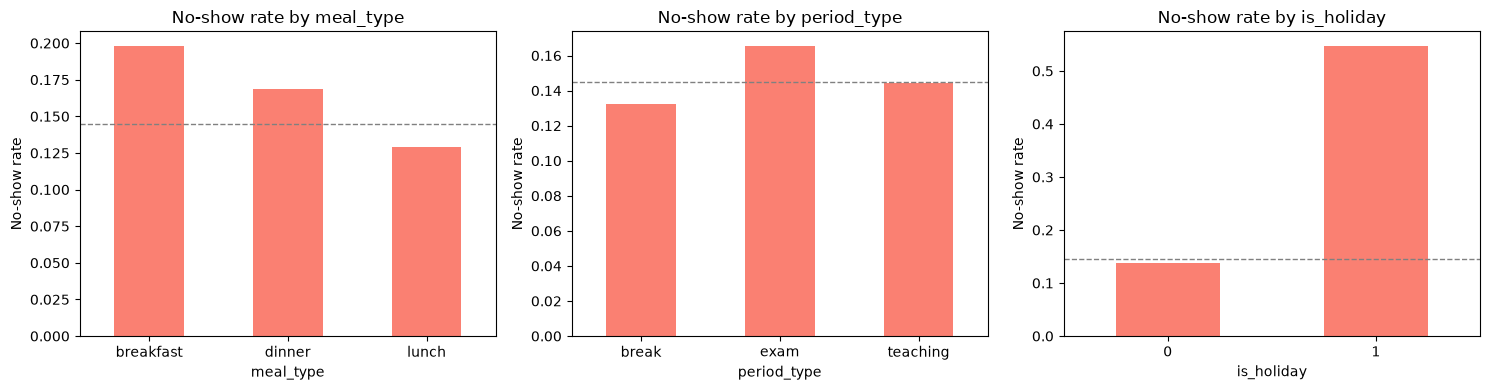

holiday
Labor Day          0.537
Nowruz Day 1       0.590
Nowruz Day 2       0.517
Nowruz Day 3       0.560
Spring Festival    0.529
Name: no-show rate, dtype: float64

In [4]:
no_show_rate = 1 - data['picked_up'].mean()
print(f'No-show rate: {no_show_rate:.1%}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ['meal_type', 'period_type', 'is_holiday']):
    rate = 1 - data.groupby(column)['picked_up'].mean()
    rate.plot(kind='bar', ax=ax, color='salmon')
    ax.set_title(f'No-show rate by {column}')
    ax.set_ylabel('No-show rate')
    ax.tick_params(axis='x', rotation=0)
    ax.axhline(no_show_rate, color='gray', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

(1 - data.groupby('holiday')['picked_up'].mean()).round(3).rename('no-show rate')

- On **holidays** more than half of the reserved meals are not picked up, compared with ~14% on normal days.
- **Breakfast** has more no-shows than lunch and dinner.
- Exam periods have slightly more no-shows than teaching weeks.

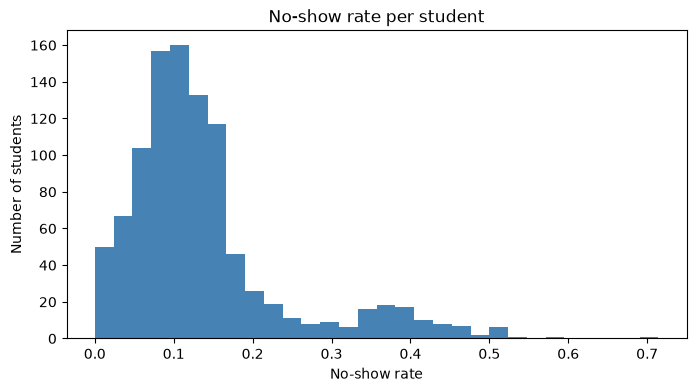

count    1000.000
mean        0.137
std         0.103
min         0.000
25%         0.077
50%         0.113
75%         0.158
max         0.714
Name: picked_up, dtype: float64

In [5]:
student_rate = 1 - data.groupby('student_id')['picked_up'].mean()

plt.figure(figsize=(8, 4))
plt.hist(student_rate, bins=30, color='steelblue')
plt.title('No-show rate per student')
plt.xlabel('No-show rate')
plt.ylabel('Number of students')
plt.show()

student_rate.describe().round(3)

Students behave very differently: most rarely miss a meal, but some miss more than half of their reservations.
A student's **own history** is therefore likely to be the most useful predictor.

## 3. Feature engineering

**Student history without leakage.** For every reservation we compute the student's pickup rate using only
the days **before** the reservation date. Students with little history are pulled towards the overall average
(smoothing with `k` pseudo-reservations), so a single missed meal does not make a new student look unreliable.

In [6]:
SMOOTHING = 5
overall_rate = data['picked_up'].mean()

daily = (data.groupby(['student_id', 'date'])
         .agg(reservations=('picked_up', 'size'), pickups=('picked_up', 'sum'))
         .reset_index()
         .sort_values(['student_id', 'date']))
grouped = daily.groupby('student_id')
daily['past_reservations'] = grouped['reservations'].cumsum() - daily['reservations']
past_pickups = grouped['pickups'].cumsum() - daily['pickups']
daily['past_pickup_rate'] = (past_pickups + SMOOTHING * overall_rate) / (daily['past_reservations'] + SMOOTHING)

data = data.merge(daily[['student_id', 'date', 'past_reservations', 'past_pickup_rate']],
                  on=['student_id', 'date'], how='left')
data[['student_id', 'date', 'picked_up', 'past_reservations', 'past_pickup_rate']].head()

,student_id,date,picked_up,past_reservations,past_pickup_rate
0,1006,2025-02-15,1,0,0.855273
1,1014,2025-02-15,1,0,0.855273
2,1014,2025-02-15,1,0,0.855273
3,1016,2025-02-15,1,0,0.855273
4,1021,2025-02-15,1,0,0.855273


In [7]:
CATEGORICAL = ['meal_type', 'meal_name', 'station', 'period_type', 'weekday']
CALENDAR_NUMERIC = ['is_dormitory', 'is_holiday']
STUDENT_NUMERIC = ['past_pickup_rate', 'past_reservations']
TARGET = 'picked_up'

## 4. Train / test split by date

The model will be used to predict **future** reservations, so it is trained on the first 80% of the semester
and tested on the last 20%. A random split would mix future days into the training data and give
over-optimistic results.

In [8]:
cutoff = data['date'].quantile(0.8)
train = data[data['date'] < cutoff]
test = data[data['date'] >= cutoff]

print(f'Train: {train.date.min().date()} – {train.date.max().date()}  ({len(train):,} reservations)')
print(f'Test:  {test.date.min().date()} – {test.date.max().date()}  ({len(test):,} reservations)')
print(f'No-show rate  train: {1 - train[TARGET].mean():.1%}   test: {1 - test[TARGET].mean():.1%}')
print('Holidays in the test period:', test['is_holiday'].sum())

Train: 2025-02-15 – 2025-05-26  (41,862 reservations)
Test:  2025-05-27 – 2025-06-20  (10,471 reservations)
No-show rate  train: 14.4%   test: 14.6%
Holidays in the test period: 0


Note: all national holidays fall in the training period, so the test score does not include holiday days,
where predictions are easiest.

## 5. Models

- Categorical features are **one-hot encoded** (the original version used `LabelEncoder`, which gives
  categories like meal names an arbitrary order that logistic regression treats as meaningful).
- `class_weight='balanced'` makes the models pay attention to the rare no-show class.
- Models are compared with **ROC AUC** and **average precision for the no-show class** — accuracy is misleading here,
  because predicting "everyone picks up" is already ~85% accurate.

In [9]:
def make_pipeline(numeric, estimator, dense=False):
    preprocess = ColumnTransformer([
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=not dense), CATEGORICAL),
        ('numeric', StandardScaler(), numeric),
    ])
    return Pipeline([('preprocess', preprocess), ('model', estimator)])


candidates = {
    'Baseline (everyone picks up)': (CALENDAR_NUMERIC, DummyClassifier(strategy='most_frequent'), False),
    'Logistic regression, no student history': (
        CALENDAR_NUMERIC, LogisticRegression(max_iter=2000, class_weight='balanced'), False),
    'Logistic regression + student history': (
        CALENDAR_NUMERIC + STUDENT_NUMERIC, LogisticRegression(max_iter=2000, class_weight='balanced'), False),
    'Gradient boosting + student history': (
        CALENDAR_NUMERIC + STUDENT_NUMERIC,
        HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE), True),
}

results, fitted = {}, {}
y_test_no_show = 1 - test[TARGET]
for name, (numeric, estimator, dense) in candidates.items():
    features = CATEGORICAL + numeric
    model = make_pipeline(numeric, estimator, dense).fit(train[features], train[TARGET])
    no_show_probability = model.predict_proba(test[features])[:, 0]
    fitted[name] = (model, features, no_show_probability)
    results[name] = {
        'ROC AUC': roc_auc_score(y_test_no_show, no_show_probability),
        'Avg. precision (no-show)': average_precision_score(y_test_no_show, no_show_probability),
    }

pd.DataFrame(results).T.round(3)

,ROC AUC,Avg. precision (no-show)
Baseline (everyone picks up),0.500,0.146
"Logistic regression, no student history",0.554,0.170
Logistic regression + student history,0.663,0.279
Gradient boosting + student history,0.656,0.265


- Without student history the model is close to random (ROC AUC ≈ 0.55).
- Adding each student's past pickup rate is what makes the model useful: average precision for no-shows roughly
  doubles compared with the no-show rate itself (~0.15, the score of a random guess).
- Gradient boosting is not better than logistic regression here, so the simpler, interpretable
  **logistic regression with student history** is selected.

## 6. Decision threshold

The model outputs a no-show probability. Where to draw the line depends on how the kitchen uses it,
so the table shows the trade-off between catching no-shows (recall) and false alarms (precision).

In [10]:
best_name = 'Logistic regression + student history'
best_model, best_features, best_probability = fitted[best_name]

rows = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    predicted_no_show = (best_probability >= threshold).astype(int)
    rows.append({
        'threshold': threshold,
        'flagged reservations': f'{predicted_no_show.mean():.1%}',
        'no-show recall': round(recall_score(y_test_no_show, predicted_no_show, zero_division=0), 3),
        'no-show precision': round(precision_score(y_test_no_show, predicted_no_show, zero_division=0), 3),
    })
pd.DataFrame(rows)

,threshold,flagged reservations,no-show recall,no-show precision
0,0.3,89.6%,0.945,0.154
1,0.4,48.3%,0.673,0.203
2,0.5,20.0%,0.389,0.284
3,0.6,10.2%,0.272,0.387
4,0.7,4.8%,0.138,0.423


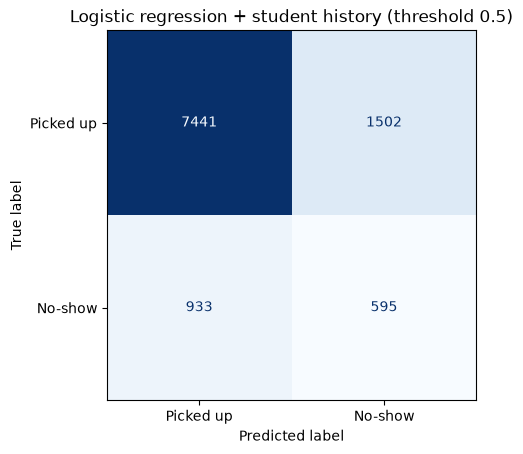

In [11]:
predicted_no_show = (best_probability >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(
    y_test_no_show, predicted_no_show, display_labels=['Picked up', 'No-show'], cmap='Blues', colorbar=False
)
plt.title(f'{best_name} (threshold 0.5)')
plt.show()

## 7. What drives no-shows?

Logistic regression coefficients (on standardized / one-hot features).
Positive values increase the probability that a meal **is picked up**; negative values point towards a no-show.

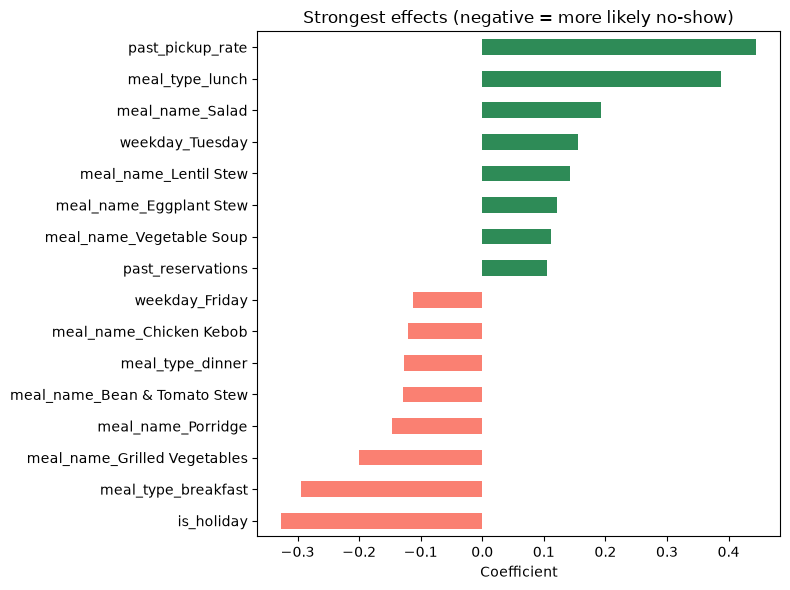

In [12]:
preprocess = best_model.named_steps['preprocess']
coefficients = pd.Series(best_model.named_steps['model'].coef_[0], index=preprocess.get_feature_names_out())
coefficients.index = coefficients.index.str.replace('categorical__', '').str.replace('numeric__', '')
top = pd.concat([coefficients.nsmallest(8), coefficients.nlargest(8)])

plt.figure(figsize=(8, 6))
top.sort_values().plot(kind='barh', color=np.where(top.sort_values() < 0, 'salmon', 'seagreen'))
plt.title('Strongest effects (negative = more likely no-show)')
plt.xlabel('Coefficient')
plt.tight_layout()
plt.show()

## Conclusion

1. About **14.5%** of reserved meals are never picked up.
2. **Holidays** are the biggest risk: more than half of the meals reserved for Nowruz, Labor Day and the Spring Festival are wasted. **Breakfast** has more no-shows than lunch and dinner.
3. A student's **own past pickup rate** is the most useful predictor. Without it the model is close to random (ROC AUC 0.55); with it, ROC AUC rises to **0.66** and average precision for no-shows to **0.28** (a random guess scores 0.15).
4. Logistic regression with one-hot encoded features performs as well as gradient boosting and is easier to interpret.
5. At a threshold of 0.5 the model flags 20% of reservations and catches about 39% of the no-shows. A stricter threshold (0.6) flags only 10% of reservations, with 39% of the flagged ones being real no-shows.

**Possible next steps:** add holiday and pre-holiday periods to the test set (e.g. a second semester), use features such as days between reservation and meal, and estimate how many portions the kitchen could save per day.